# Text Preprocessing for Conversation Sentiment Analysis

## Objective

The objective of this notebook is to clean and prepare conversational text
for Natural Language Processing and sentiment classification.

The preprocessing pipeline includes:

- Text normalization
- Lowercase conversion
- URL removal
- Special character handling
- Tokenization
- Stopword analysis
- Lemmatization
- Preparation of clean text for machine learning

In [17]:
# ==========================================
# 1. IMPORT LIBRARIES
# ==========================================

import pandas as pd
import numpy as np
import re
import nltk

from pathlib import Path

print("Preprocessing libraries imported successfully!")

Preprocessing libraries imported successfully!


In [18]:
# ==========================================
# 2. LOAD DATASET
# ==========================================

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "raw"

train_df = pd.read_csv(DATA_DIR / "train_sent_emo.csv")
dev_df = pd.read_csv(DATA_DIR / "dev_sent_emo.csv")
test_df = pd.read_csv(DATA_DIR / "test_sent_emo.csv")

print("Dataset loaded successfully!")
print("Training records:", len(train_df))

Dataset loaded successfully!
Training records: 9989


In [19]:
# ==========================================
# 3. DOWNLOAD NLP RESOURCES
# ==========================================

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("NLTK resources downloaded successfully!")

NLTK resources downloaded successfully!


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\sansm\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\sansm\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\sansm\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\sansm\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\sansm\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\sansm\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [20]:
# ==========================================
# 4. TEXT CLEANING FUNCTION
# ==========================================

def clean_text(text):
    if pd.isna(text):
        return ""

    text = str(text)

    # Convert text to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r'https?://\S+|www\.\S+', '', text)

    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    return text


print("Text cleaning function created!")

Text cleaning function created!


In [21]:
# ==========================================
# 5. TOKENIZATION
# ==========================================

from nltk.tokenize import word_tokenize

sample_text = "I really love this movie! It is amazing."

tokens = word_tokenize(sample_text)

print("Original text:")
print(sample_text)

print("\nTokens:")
print(tokens)

Original text:
I really love this movie! It is amazing.

Tokens:
['I', 'really', 'love', 'this', 'movie', '!', 'It', 'is', 'amazing', '.']


In [7]:
# ==========================================
# 6. STOPWORD ANALYSIS
# ==========================================

from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))

# Protect sentiment-changing words
negation_words = {
    "not", "no", "nor", "never", "none",
    "n't", "don't", "doesn't", "didn't",
    "isn't", "wasn't", "aren't", "weren't",
    "won't", "wouldn't", "couldn't", "shouldn't",
    "can't", "cannot", "without"
}

# Remove protected words from stopword set
stop_words = stop_words - negation_words

print("Total stopwords:", len(stop_words))
print("Protected negation words:", negation_words)

Total stopwords: 184
Protected negation words: {'not', "couldn't", "shouldn't", "aren't", "won't", "wasn't", 'none', "can't", "doesn't", 'never', 'no', "isn't", "don't", "wouldn't", 'without', 'nor', "didn't", "n't", "weren't", 'cannot'}


In [8]:
# ==========================================
# 7. STOPWORD REMOVAL TEST
# ==========================================

sample_text = "I am not happy with this movie and I never liked it."

tokens = word_tokenize(sample_text.lower())

filtered_tokens = [
    word for word in tokens
    if word not in stop_words
]

print("Original sentence:")
print(sample_text)

print("\nOriginal tokens:")
print(tokens)

print("\nAfter stopword removal:")
print(filtered_tokens)

Original sentence:
I am not happy with this movie and I never liked it.

Original tokens:
['i', 'am', 'not', 'happy', 'with', 'this', 'movie', 'and', 'i', 'never', 'liked', 'it', '.']

After stopword removal:
['not', 'happy', 'movie', 'never', 'liked', '.']


In [9]:
# ==========================================
# 8. LEMMATIZATION
# ==========================================

from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()

print("Lemmatizer initialized successfully!")

Lemmatizer initialized successfully!


In [10]:
# Test lemmatization

words = ["playing", "studies", "cars", "running", "loved", "better"]

lemmatized_words = [
    lemmatizer.lemmatize(word)
    for word in words
]

print("Original words:   ", words)
print("Lemmatized words: ", lemmatized_words)

Original words:    ['playing', 'studies', 'cars', 'running', 'loved', 'better']
Lemmatized words:  ['playing', 'study', 'car', 'running', 'loved', 'better']


In [11]:
# ==========================================
# POS-AWARE LEMMATIZATION
# ==========================================

from nltk import pos_tag
from nltk.corpus import wordnet

# Download POS tagging resource
nltk.download("averaged_perceptron_tagger_eng")

def get_wordnet_pos(word):
    tag = pos_tag([word])[0][1][0].upper()

    tag_map = {
        "J": wordnet.ADJ,
        "V": wordnet.VERB,
        "N": wordnet.NOUN,
        "R": wordnet.ADV
    }

    return tag_map.get(tag, wordnet.NOUN)


def lemmatize_words(words):
    return [
        lemmatizer.lemmatize(word, get_wordnet_pos(word))
        for word in words
    ]

test_words = ["playing", "studies", "cars", "running", "loved", "better"]

result = lemmatize_words(test_words)

print("Original words:  ", test_words)
print("Lemmatized words:", result)

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\sansm\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


Original words:   ['playing', 'studies', 'cars', 'running', 'loved', 'better']
Lemmatized words: ['play', 'study', 'car', 'run', 'love', 'well']


In [12]:
# ==========================================
# 9. COMPLETE PREPROCESSING PIPELINE
# ==========================================

from nltk.tokenize import word_tokenize
from nltk import pos_tag
from nltk.corpus import wordnet
import re

def preprocess_text(text):
    if pd.isna(text):
        return ""

    # Step 1: Text cleaning
    text = clean_text(text)

    # Step 2: Tokenization
    tokens = word_tokenize(text)

    # Step 3: Remove punctuation but preserve negations
    tokens = [
        word for word in tokens
        if word.isalpha() or word in negation_words
    ]

    # Step 4: Stopword removal
    tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    # Step 5: POS tagging
    tagged_words = pos_tag(tokens)

    # Step 6: Lemmatization
    processed_words = []

    for word, tag in tagged_words:

        tag_map = {
            "J": wordnet.ADJ,
            "V": wordnet.VERB,
            "N": wordnet.NOUN,
            "R": wordnet.ADV
        }

        wordnet_tag = tag_map.get(tag[0], wordnet.NOUN)

        lemma = lemmatizer.lemmatize(word, wordnet_tag)

        processed_words.append(lemma)

    # Step 7: Return final processed text
    return " ".join(processed_words)


print("Complete preprocessing pipeline created successfully!")

Complete preprocessing pipeline created successfully!


In [13]:
# ==========================================
# 10. TEST PREPROCESSING PIPELINE
# ==========================================

sample_sentences = [
    "I really love this amazing movie!",
    "I am not happy with this product.",
    "They were playing football yesterday.",
    "She never liked the terrible experience."
]

for sentence in sample_sentences:

    processed = preprocess_text(sentence)

    print("Original :", sentence)
    print("Processed:", processed)
    print("-" * 60)

Original : I really love this amazing movie!
Processed: really love amazing movie
------------------------------------------------------------
Original : I am not happy with this product.
Processed: not happy product
------------------------------------------------------------
Original : They were playing football yesterday.
Processed: play football yesterday
------------------------------------------------------------
Original : She never liked the terrible experience.
Processed: never like terrible experience
------------------------------------------------------------


In [14]:
# ==========================================
# 11. APPLY PREPROCESSING TO MELD DATASET
# ==========================================

train_df["Cleaned_Utterance"] = train_df["Utterance"].apply(
    preprocess_text
)

dev_df["Cleaned_Utterance"] = dev_df["Utterance"].apply(
    preprocess_text
)

test_df["Cleaned_Utterance"] = test_df["Utterance"].apply(
    preprocess_text
)

print("Preprocessing applied successfully!")

Preprocessing applied successfully!


In [15]:
# ==========================================
# 12. ORIGINAL VS PREPROCESSED TEXT
# ==========================================

comparison_df = train_df[
    ["Utterance", "Cleaned_Utterance", "Sentiment", "Emotion"]
].head(15)

display(comparison_df)

,Utterance,Cleaned_Utterance,Sentiment,Emotion
0,also I was the point person on my company’s tr...,also point person company transition system,neutral,neutral
1,You must’ve had your hands full.,must hand full,neutral,neutral
2,That I did. That I did.,,neutral,neutral
3,So let’s talk a little bit about your duties.,let talk little bit duty,neutral,neutral
4,My duties? All right.,duty right,positive,surprise
5,"Now you’ll be heading a whole division, so you...",head whole division lot duty,neutral,neutral
6,I see.,see,neutral,neutral
7,But there’ll be perhaps 30 people under you so...,perhaps people dump certain amount,neutral,neutral
8,Good to know.,good know,neutral,neutral
9,We can go into detail,go detail,neutral,neutral


In [16]:
# ==========================================
# 13. SAVE PREPROCESSED DATASETS
# ==========================================

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

train_df.to_csv(PROCESSED_DIR / "train_processed.csv", index=False)
dev_df.to_csv(PROCESSED_DIR / "dev_processed.csv", index=False)
test_df.to_csv(PROCESSED_DIR / "test_processed.csv", index=False)

print("Processed datasets saved successfully!")
print("Location:", PROCESSED_DIR)

Processed datasets saved successfully!
Location: c:\Users\sansm\Desktop\NLP PROJECT CHATGPT\Conversation_Sentiment_Analysis\data\processed


In [5]:
import pandas as pd

# Find all DataFrames currently loaded in the notebook
for name, obj in globals().items():
    if isinstance(obj, pd.DataFrame):
        print(f"\nDataFrame: {name}")
        print("Shape:", obj.shape)
        print("Columns:", obj.columns.tolist())

In [6]:
from pathlib import Path

# Search for CSV files in the project
project_path = Path("..")

csv_files = list(project_path.rglob("*.csv"))

for file in csv_files:
    print(file)

..\data\processed\dev_processed.csv
..\data\processed\test_processed.csv
..\data\processed\train_processed.csv
..\data\raw\dev_sent_emo.csv
..\data\raw\test_sent_emo.csv
..\data\raw\train_sent_emo.csv


In [7]:
import pandas as pd

# Load original MELD datasets
emotion_train = pd.read_csv("../data/raw/train_sent_emo.csv")
emotion_dev = pd.read_csv("../data/raw/dev_sent_emo.csv")
emotion_test = pd.read_csv("../data/raw/test_sent_emo.csv")

# Inspect the emotion labels
print("Training columns:")
print(emotion_train.columns.tolist())

print("\nEmotion distribution in training data:")
print(emotion_train["Emotion"].value_counts())

print("\nTraining shape:", emotion_train.shape)
print("Validation shape:", emotion_dev.shape)
print("Testing shape:", emotion_test.shape)

Training columns:
['Sr No.', 'Utterance', 'Speaker', 'Emotion', 'Sentiment', 'Dialogue_ID', 'Utterance_ID', 'Season', 'Episode', 'StartTime', 'EndTime']

Emotion distribution in training data:
Emotion
neutral     4710
joy         1743
surprise    1205
anger       1109
sadness      683
disgust      271
fear         268
Name: count, dtype: int64

Training shape: (9989, 11)
Validation shape: (1109, 11)
Testing shape: (2610, 11)


Emotion classes: ['anger', 'disgust', 'fear', 'joy', 'neutral', 'sadness', 'surprise']
Number of emotion classes: 7

Emotion distribution:


,Count
Emotion,
neutral,4710
joy,1743
surprise,1205
anger,1109
sadness,683
disgust,271
fear,268


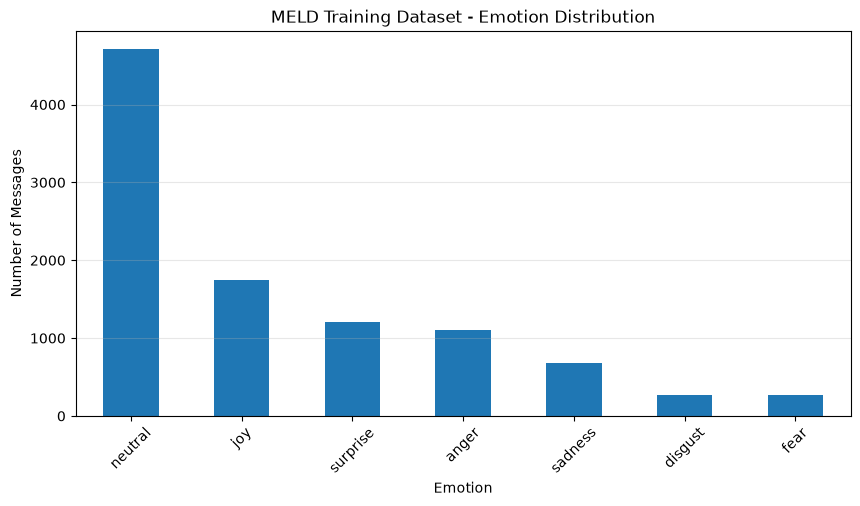

In [8]:
# Display all emotion categories
emotion_labels = sorted(emotion_train["Emotion"].unique())

print("Emotion classes:", emotion_labels)
print("Number of emotion classes:", len(emotion_labels))

# Check class distribution
emotion_counts = emotion_train["Emotion"].value_counts()

print("\nEmotion distribution:")
display(emotion_counts.to_frame(name="Count"))

# Visualize the distribution
import matplotlib.pyplot as plt

emotion_counts.plot(kind="bar", figsize=(10, 5))
plt.title("MELD Training Dataset - Emotion Distribution")
plt.xlabel("Emotion")
plt.ylabel("Number of Messages")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.show()

In [9]:
import re

# Simple text cleaning for emotion recognition
def clean_emotion_text(text):

    text = str(text).lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text)

    return text.strip()


# Clean utterances in all three datasets
emotion_train["clean_text"] = emotion_train["Utterance"].apply(clean_emotion_text)
emotion_dev["clean_text"] = emotion_dev["Utterance"].apply(clean_emotion_text)
emotion_test["clean_text"] = emotion_test["Utterance"].apply(clean_emotion_text)


# Display examples
display(
    emotion_train[["Utterance", "clean_text", "Emotion"]].head(10)
)

print("Emotion training preprocessing completed!")

,Utterance,clean_text,Emotion
0,also I was the point person on my company’s tr...,also i was the point person on my company’s tr...,neutral
1,You must’ve had your hands full.,you must’ve had your hands full.,neutral
2,That I did. That I did.,that i did. that i did.,neutral
3,So let’s talk a little bit about your duties.,so let’s talk a little bit about your duties.,neutral
4,My duties? All right.,my duties? all right.,surprise
5,"Now you’ll be heading a whole division, so you...","now you’ll be heading a whole division, so you...",neutral
6,I see.,i see.,neutral
7,But there’ll be perhaps 30 people under you so...,but there’ll be perhaps 30 people under you so...,neutral
8,Good to know.,good to know.,neutral
9,We can go into detail,we can go into detail,neutral


Emotion training preprocessing completed!


In [10]:
# Emotion label mapping
EMOTION_LABELS = [
    "anger",
    "disgust",
    "fear",
    "joy",
    "neutral",
    "sadness",
    "surprise"
]

emotion_label_map = {
    emotion: index
    for index, emotion in enumerate(EMOTION_LABELS)
}

emotion_id_map = {
    index: emotion
    for emotion, index in emotion_label_map.items()
}

print("Emotion label mapping:")
print(emotion_label_map)

Emotion label mapping:
{'anger': 0, 'disgust': 1, 'fear': 2, 'joy': 3, 'neutral': 4, 'sadness': 5, 'surprise': 6}


In [11]:
# Normalize emotion label casing
for df in [emotion_train, emotion_dev, emotion_test]:
    df["Emotion"] = df["Emotion"].str.lower().str.strip()

# Convert emotion labels to numeric IDs
emotion_train["emotion_id"] = emotion_train["Emotion"].map(emotion_label_map)
emotion_dev["emotion_id"] = emotion_dev["Emotion"].map(emotion_label_map)
emotion_test["emotion_id"] = emotion_test["Emotion"].map(emotion_label_map)

# Verify that all labels were mapped successfully
print("Missing training labels:", emotion_train["emotion_id"].isna().sum())
print("Missing validation labels:", emotion_dev["emotion_id"].isna().sum())
print("Missing testing labels:", emotion_test["emotion_id"].isna().sum())

display(
    emotion_train[["Emotion", "emotion_id"]].drop_duplicates().sort_values("emotion_id")
)

Missing training labels: 0
Missing validation labels: 0
Missing testing labels: 0


,Emotion,emotion_id
67,anger,0
27,disgust,1
10,fear,2
23,joy,3
0,neutral,4
15,sadness,5
4,surprise,6


In [12]:
from pathlib import Path

# Create a separate folder for emotion datasets
emotion_output_dir = Path("../data/processed/emotion")
emotion_output_dir.mkdir(parents=True, exist_ok=True)

# Save training, validation, and test data
emotion_train.to_csv(
    emotion_output_dir / "emotion_train.csv",
    index=False
)

emotion_dev.to_csv(
    emotion_output_dir / "emotion_dev.csv",
    index=False
)

emotion_test.to_csv(
    emotion_output_dir / "emotion_test.csv",
    index=False
)

print("Emotion datasets saved successfully!")

print("Saved files:")
for file in emotion_output_dir.glob("*.csv"):
    print(file, "|", file.stat().st_size, "bytes")

Emotion datasets saved successfully!
Saved files:
..\data\processed\emotion\emotion_dev.csv | 171528 bytes
..\data\processed\emotion\emotion_test.csv | 416308 bytes
..\data\processed\emotion\emotion_train.csv | 1570564 bytes
